In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import tensorflow as tf

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC_DIR = ROOT / "src"

sys.path.insert(0, str(SRC_DIR))

from prepare_data import train_ds, val_ds

OUTPUT_DIR = ROOT / "models" / "experiments"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 30

print("Project root:", ROOT)
print("Experiment outputs:", OUTPUT_DIR)
print("TensorFlow:", tf.__version__)

I0000 00:00:1792497515.912089  343702 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792497515.913131  343702 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792497515.944885  343702 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792497517.509661  343702 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

Found 17034 files belonging to 6 classes.
Using 11924 files for training.
Found 17034 files belonging to 6 classes.
Using 5110 files for validation.


E0000 00:00:1792497518.884513  343702 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



Project root: /home/elgmouri/projects/intel-image-classification-cnn
Experiment outputs: /home/elgmouri/projects/intel-image-classification-cnn/models/experiments
TensorFlow: 2.22.0-rc0


In [2]:
def build_model(dropout_rate=0.3, learning_rate=0.001):
    layers = tf.keras.layers

    model = tf.keras.Sequential([
        layers.Input(shape=(150, 150, 3)),

        layers.Conv2D(32, kernel_size=3, padding="same"),
        layers.ReLU(),
        layers.MaxPooling2D(pool_size=2),

        layers.Conv2D(64, kernel_size=3, padding="same"),
        layers.ReLU(),
        layers.MaxPooling2D(pool_size=2),

        layers.Conv2D(128, kernel_size=3, padding="same"),
        layers.ReLU(),
        layers.MaxPooling2D(pool_size=2),

        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(dropout_rate),
        layers.Dense(6, activation="softmax"),
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    return model

In [3]:
EXPERIMENTS = {
    "baseline": {
        "dropout": 0.3,
        "learning_rate": 0.001,
    },
    "dropout_050": {
        "dropout": 0.5,
        "learning_rate": 0.001,
    },
    "lr_0003": {
        "dropout": 0.3,
        "learning_rate": 0.0003,
    },
}

In [4]:
def train_experiment(name, config):
    print(f"\n{'=' * 50}")
    print(f"Experiment: {name}")
    print(f"Configuration: {config}")
    print(f"{'=' * 50}")

    model = build_model(
        dropout_rate=config["dropout"],
        learning_rate=config["learning_rate"],
    )

    best_model_path = OUTPUT_DIR / f"{name}.keras"
    history_path = OUTPUT_DIR / f"{name}_history.csv"
    curve_path = OUTPUT_DIR / f"{name}_curves.png"

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.2,
            patience=2,
            min_lr=1e-6,
        ),
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(best_model_path),
            monitor="val_loss",
            save_best_only=True,
        ),
    ]

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=1,
    )

    # Save the model with the restored best weights.
    model.save(best_model_path)

    history_df = pd.DataFrame(history.history)
    history_df.to_csv(history_path, index_label="epoch")

    # Plot training and validation curves.
    epochs = range(1, len(history.history["loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, history.history["loss"], label="Training")
    axes[0].plot(epochs, history.history["val_loss"], label="Validation")
    axes[0].set_title(f"{name}: Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(epochs, history.history["accuracy"], label="Training")
    axes[1].plot(
        epochs,
        history.history["val_accuracy"],
        label="Validation",
    )
    axes[1].set_title(f"{name}: Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    fig.tight_layout()
    fig.savefig(curve_path, dpi=150)
    plt.show()
    plt.close(fig)

    # Select the epoch with the lowest validation loss.
    best_epoch_index = int(
        np.argmin(history.history["val_loss"])
    )

    result = {
        "experiment": name,
        "dropout": config["dropout"],
        "learning_rate": config["learning_rate"],
        "epochs_trained": len(history.history["loss"]),
        "best_epoch": best_epoch_index + 1,
        "best_val_loss": min(history.history["val_loss"]),
        "val_accuracy_at_best_loss": (
            history.history["val_accuracy"][best_epoch_index]
        ),
        "model_path": str(best_model_path),
    }

    return result


Experiment: baseline
Configuration: {'dropout': 0.3, 'learning_rate': 0.001}
Epoch 1/30


/home/elgmouri/projects/intel-image-classification-cnn/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


373/373 ━━━━━━━━━━━━━━━━━━━━ 117s 310ms/step - accuracy: 0.4368 - loss: 1.3284 - val_accuracy: 0.5238 - val_loss: 1.2690 - learning_rate: 0.0010
Epoch 2/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 98s 263ms/step - accuracy: 0.5541 - loss: 1.0957 - val_accuracy: 0.5059 - val_loss: 1.2529 - learning_rate: 0.0010
Epoch 3/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 99s 264ms/step - accuracy: 0.5981 - loss: 1.0133 - val_accuracy: 0.5988 - val_loss: 1.0518 - learning_rate: 0.0010
Epoch 4/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 99s 264ms/step - accuracy: 0.6374 - loss: 0.9354 - val_accuracy: 0.6477 - val_loss: 0.9294 - learning_rate: 0.0010
Epoch 5/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 99s 265ms/step - accuracy: 0.6602 - loss: 0.8798 - val_accuracy: 0.7090 - val_loss: 0.7896 - learning_rate: 0.0010
Epoch 6/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 100s 267ms/step - accuracy: 0.6723 - loss: 0.8538 - val_accuracy: 0.7160 - val_loss: 0.7656 - learning_rate: 0.0010
Epoch 7/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 100s 267ms/step - accuracy: 0.6947 - lo

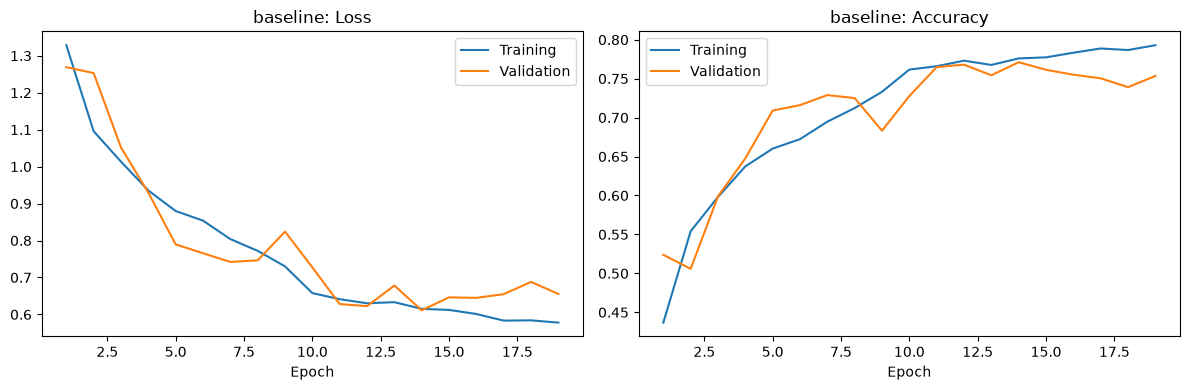


Experiment: dropout_050
Configuration: {'dropout': 0.5, 'learning_rate': 0.001}
Epoch 1/30


/home/elgmouri/projects/intel-image-classification-cnn/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


373/373 ━━━━━━━━━━━━━━━━━━━━ 100s 266ms/step - accuracy: 0.4025 - loss: 1.4008 - val_accuracy: 0.4953 - val_loss: 1.2686 - learning_rate: 0.0010
Epoch 2/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 99s 266ms/step - accuracy: 0.5096 - loss: 1.1772 - val_accuracy: 0.4879 - val_loss: 1.3046 - learning_rate: 0.0010
Epoch 3/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 99s 265ms/step - accuracy: 0.5476 - loss: 1.0979 - val_accuracy: 0.6137 - val_loss: 0.9585 - learning_rate: 0.0010
Epoch 4/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 99s 266ms/step - accuracy: 0.5959 - loss: 1.0100 - val_accuracy: 0.5969 - val_loss: 1.0112 - learning_rate: 0.0010
Epoch 5/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 99s 266ms/step - accuracy: 0.6266 - loss: 0.9507 - val_accuracy: 0.6645 - val_loss: 0.8587 - learning_rate: 0.0010
Epoch 6/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 100s 267ms/step - accuracy: 0.6537 - loss: 0.9072 - val_accuracy: 0.6750 - val_loss: 0.8624 - learning_rate: 0.0010
Epoch 7/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 99s 265ms/step - accuracy: 0.6741 - los

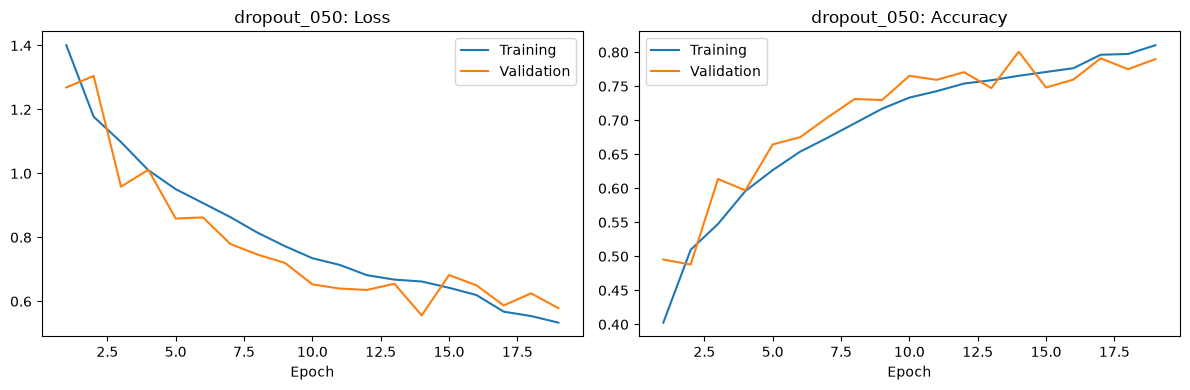


Experiment: lr_0003
Configuration: {'dropout': 0.3, 'learning_rate': 0.0003}
Epoch 1/30


/home/elgmouri/projects/intel-image-classification-cnn/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


373/373 ━━━━━━━━━━━━━━━━━━━━ 100s 267ms/step - accuracy: 0.4041 - loss: 1.4034 - val_accuracy: 0.4070 - val_loss: 1.5591 - learning_rate: 3.0000e-04
Epoch 2/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 100s 267ms/step - accuracy: 0.5042 - loss: 1.1876 - val_accuracy: 0.4410 - val_loss: 1.5444 - learning_rate: 3.0000e-04
Epoch 3/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 100s 267ms/step - accuracy: 0.5541 - loss: 1.1030 - val_accuracy: 0.5746 - val_loss: 1.1333 - learning_rate: 3.0000e-04
Epoch 4/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 99s 266ms/step - accuracy: 0.5789 - loss: 1.0546 - val_accuracy: 0.5668 - val_loss: 1.1017 - learning_rate: 3.0000e-04
Epoch 5/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 100s 267ms/step - accuracy: 0.5960 - loss: 1.0184 - val_accuracy: 0.5723 - val_loss: 1.1544 - learning_rate: 3.0000e-04
Epoch 6/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 99s 266ms/step - accuracy: 0.6114 - loss: 0.9870 - val_accuracy: 0.5922 - val_loss: 1.0645 - learning_rate: 3.0000e-04
Epoch 7/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 100s 268ms/st

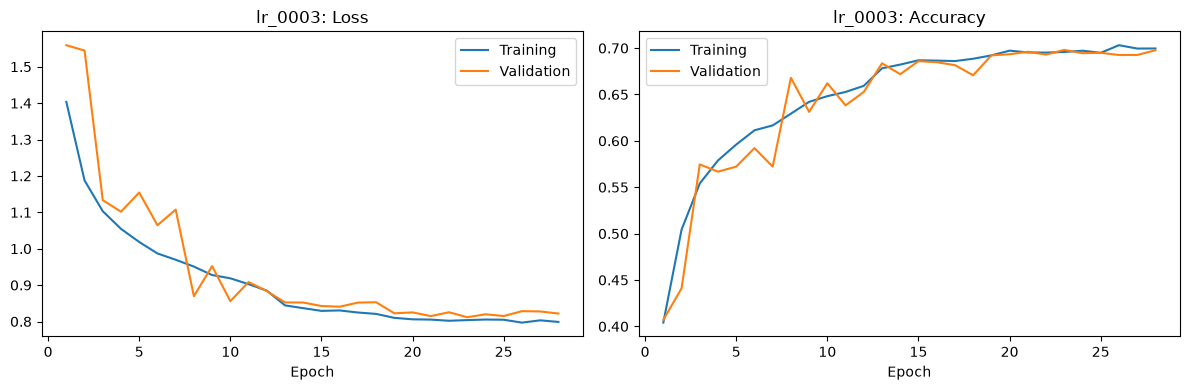

All experiments completed.


In [5]:
results = []

for name, config in EXPERIMENTS.items():
    result = train_experiment(name, config)
    results.append(result)

    # Save intermediate results in case you stop before all
    # experiments finish.
    pd.DataFrame(results).to_csv(
        OUTPUT_DIR / "experiment_results.csv",
        index=False,
    )

print("All experiments completed.")

In [7]:
results_df = pd.read_csv(
    OUTPUT_DIR / "experiment_results.csv"
)

results_df = results_df.sort_values(
    by="best_val_loss",
    ascending=True,
)

display(results_df)

,experiment,dropout,learning_rate,epochs_trained,best_epoch,best_val_loss,val_accuracy_at_best_loss,model_path
1,dropout_050,0.5,0.0010,19,14,0.555917,0.800781,/home/elgmouri/projects/intel-image-classifica...
0,baseline,0.3,0.0010,19,14,0.611223,0.771094,/home/elgmouri/projects/intel-image-classifica...
2,lr_0003,0.3,0.0003,28,23,0.811767,0.698047,/home/elgmouri/projects/intel-image-classifica...


higher dropout improved validation performance but did not improve test accuracy.